<a href="https://colab.research.google.com/github/muiddd/5thSemester_MachineLearning/blob/main/Week11/01_AbdulMuid_P11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Week 11: Klasifikasi 2**

* **Nama:** Abdul Muid
* **NIM:** 244107020006
* **Kelas:** TI 3A
* **Mata Kuliah:** Machine Learning

---

>Praktikum 1

In [1]:
# Langkah 1 - Import Library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

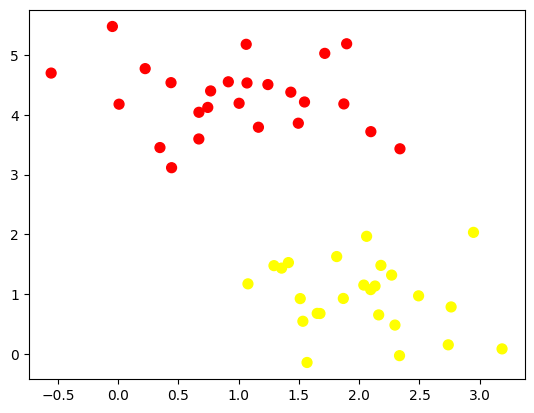

In [2]:
# Langkah 2 - Membuat Data Dummy
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

(-1.0, 3.5)

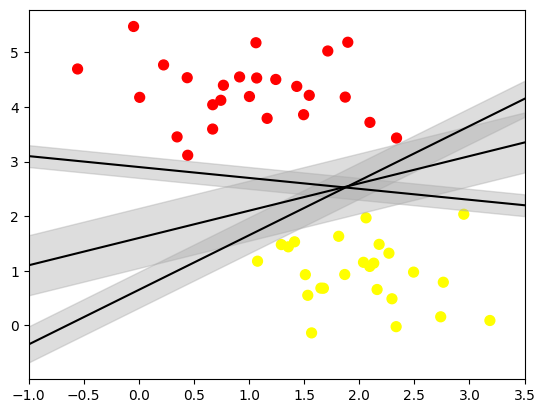

In [3]:
# Langkah 4 - Ilustrasi Margin
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
  yfit = m * xfit + b
  plt.plot(xfit, yfit, '-k')
  plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)

In [4]:
# Langkah 5 - Fitting Model
from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

In [5]:
# Langkah 6 - Membuat Fungsi Pembantu Visualisasi
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='k');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

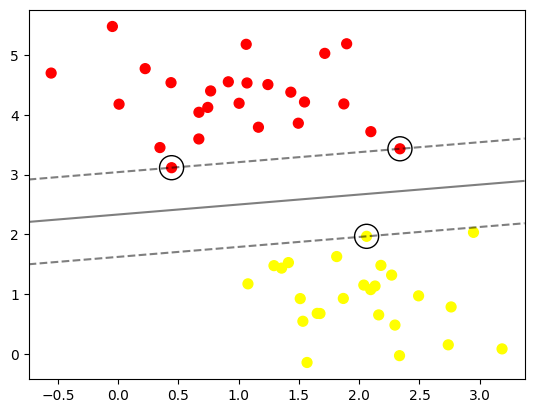

In [6]:
# Langkah 7 - Plotting Hasil Model
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)

In [7]:
# Langkah 8 - Mengetahui Koordinat Support Vectors
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

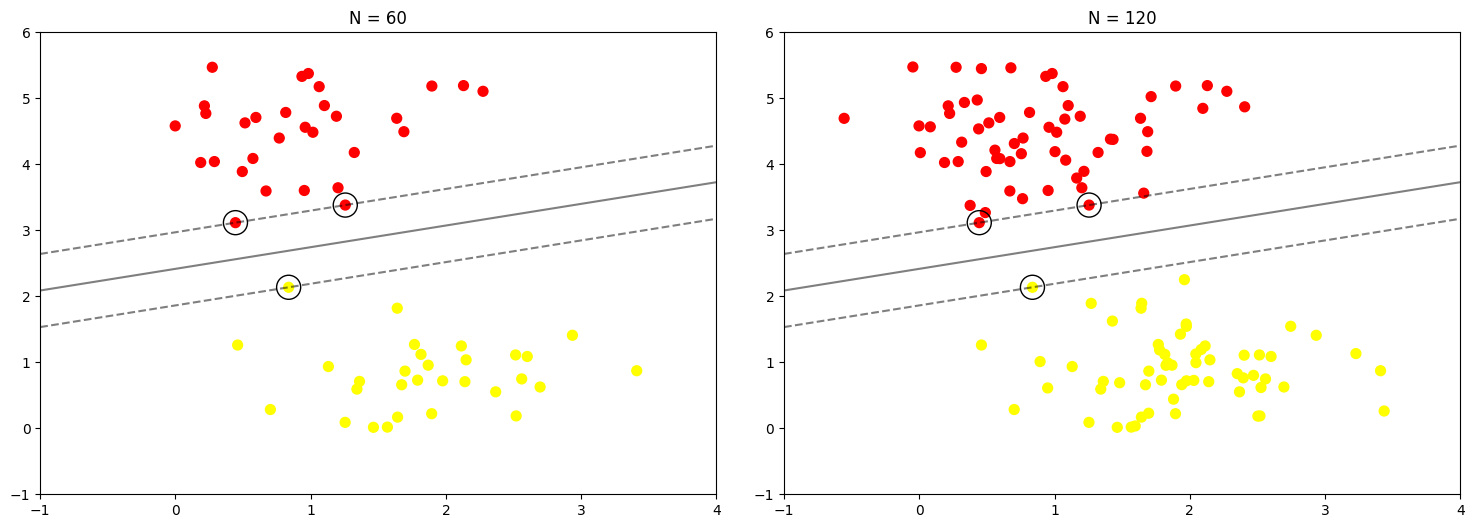

In [8]:
# Langkah 9 - Eksperimen Pengaruh Jumlah Data terhadap Model
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))

In [9]:
# Langkah 10 - Visualisasi Interaktif Menggunakan Widget
from ipywidgets import interact, fixed
interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

>Praktikum 2

In [10]:
# Langkah 1a - Import Library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

In [11]:
# Langkah 1b - Buat Kembali Fungsi Plotting
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='k')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

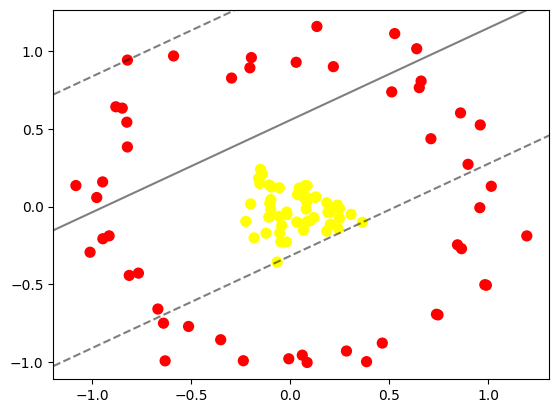

In [12]:
# Langkah 1c - Buat Data Dummy Non-Linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False)

In [13]:
# Langkah 1d - Proyeksi Radial 3D
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

r = np.exp(-(X**2).sum(1))

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20, 10], azim=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 0.51224449,  0.73649893],
       [ 0.19985298, -0.03572418],
       [ 0.85921323,  0.6014671 ],
       [ 0.98174311, -0.50195898],
       [ 0.04576458,  0.11939401],
       [ 0.07678663,  0.13534881],
       [ 0.18421726, -0.15784091],
       [ 0.73774611, -0.69180959],
       [ 0.30672275, -0.0498554 ],
       [-0.19567597,  0.95693494],
       [ 0.95659865, -0.00722272],
       [-0.1819525 , -0.20087669],
       [-0.94466758, -0.20659664],
       [-0.8237615 ,  0.54202783],
       [ 0.13477616,  1.15664173],
       [-0.23627046, -0.99011581],
       [ 0.98955486, -0.5050537 ],
       [-0.8792609 ,  0.64093013],
       [-0.05582703, -0.06310222],
       [-1.00920194, -0.29329214],
       [ 0.28390549, -0.92768427],
       [ 0.24834166, -0.07446204],
       [-0.81157918, -0.44209034],
       [-0.20311099,  0.89123839],
       [ 0.08069968, -0.01584674],
       [-0.63880716, -0.74893288],
       [ 0.06732184,  0.06143655],
       [-0.04282499, -0.12019109],
       [-0.09748319,  0.04417231],
       [-0.05430333,  0.12103321],
       [-0.51242276, -0.76993862],
       [-0.5880133 ,  0.96728353],
       [-0.84696732,  0.63219923],
       [-1.08065124,  0.13503568],
       [-0.91304969, -0.18800916],
       [ 0.23804152,  0.00980444],
       [-0.0188036 , -0.22718081],
       [ 0.19048648, -0.03627181],
       [ 0.08555921, -1.0013319 ],
       [ 0.03710146,  0.07764226],
       [-0.35034711, -0.85528995],
       [-0.04696618, -0.22633195],
       [ 0.36418848, -0.10139349],
       [-0.19944751,  0.01717809],
       [-0.94572947,  0.158413  ],
       [-0.15312924,  0.14784811],
       [-0.10309652,  0.0206999 ],
       [ 0.65105854,  0.76362389],
       [-0.63059784, -0.99082794],
       [-0.06578128, -0.35606028],
       [ 0.89711893,  0.27131368],
       [-0.09781569, -0.01940817],
       [ 0.24854698, -0.01173195],
       [ 1.01431734,  0.13034739],
       [-0.14033846,  0.21005739],
       [ 0.95862995,  0.52428835],
       [ 0.74564856, -0.6957053 ],
       [-0.82103464,  0.38291265],
       [-0.76523602, -0.42750426],
       [ 0.06113192, -0.95437965],
       [ 0.08361534,  0.02957865],
       [ 0.20276037, -0.11302577],
       [ 0.0857741 , -0.09709222],
       [ 0.18481916,  0.0248768 ],
       [ 0.38520161, -0.99616918],
       [ 0.63815737,  1.01372734],
       [ 0.12553321,  0.05906558],
       [-0.22391485, -0.09495601],
       [-0.66719252, -0.65793992],
       [ 0.66025631,  0.80609944],
       [ 0.10167324, -0.08991898],
       [ 0.2423198 , -0.14214068],
       [-0.15885678,  0.18129037],
       [-0.14964116,  0.23897033],
       [ 0.20194486, -0.03049477],
       [-0.29556211,  0.82546932],
       [ 0.84382016, -0.24573407],
       [ 0.52719504,  1.11101799],
       [-0.12175312, -0.17115452],
       [-0.01632807, -0.05109546],
       [ 0.06686336, -0.15129426],
       [ 0.08578733,  0.13349842],
       [ 0.217833  ,  0.89853861],
       [-0.09481065,  0.12609682],
       [-0.01751861, -0.03476259],
       [ 0.4646319 , -0.87668286],
       [ 0.13035459,  0.06112402],
       [-0.82078698,  0.94085865],
       [ 0.03332742, -0.09908482],
       [ 0.08171444,  0.05979491],
       [-0.97545083,  0.05804945],
       [ 0.03028251,  0.92676252],
       [-0.10781337, -0.06802368],
       [-0.10611058,  0.13898937],
       [ 1.19339792, -0.1883673 ],
       [ 0.11941032, -0.07115974],
       [ 0.70977354,  0.43565179],
       [-0.00695198, -0.9777253 ],
       [ 0.86409167, -0.2703521 ],
       [-0.05292073, -0.1696667 ]]), y=array([0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0,
       1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1]))>

In [14]:
# Langkah 2 - Fitting Model dengan Kernel RBF
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

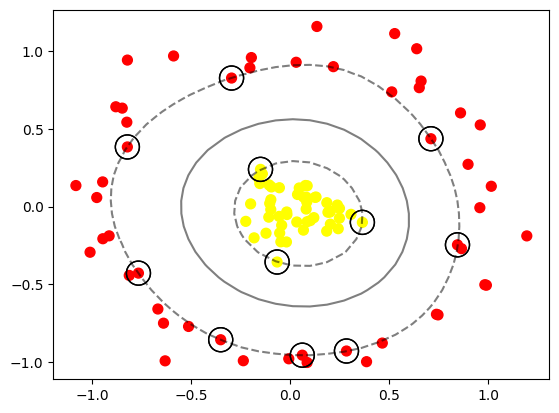

In [15]:
# Langkah 3 - Plotting Hasil Decision Boundaries dari Kernel RBF
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none', edgecolors='k')

>Praktikum 3

In [16]:
# Langkah 1 - Import Library dan Buat Fungsi Plotting
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='k')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

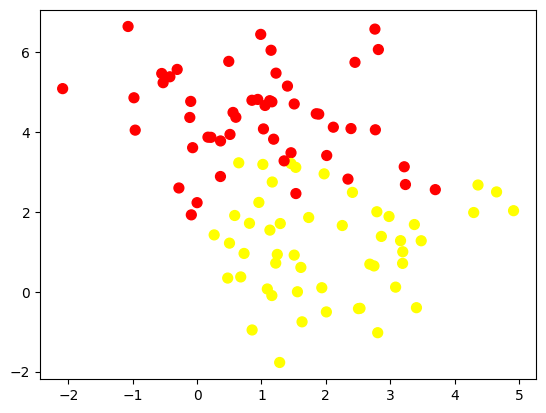

In [17]:
# Langkah 2 - Buat Data Dummy
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

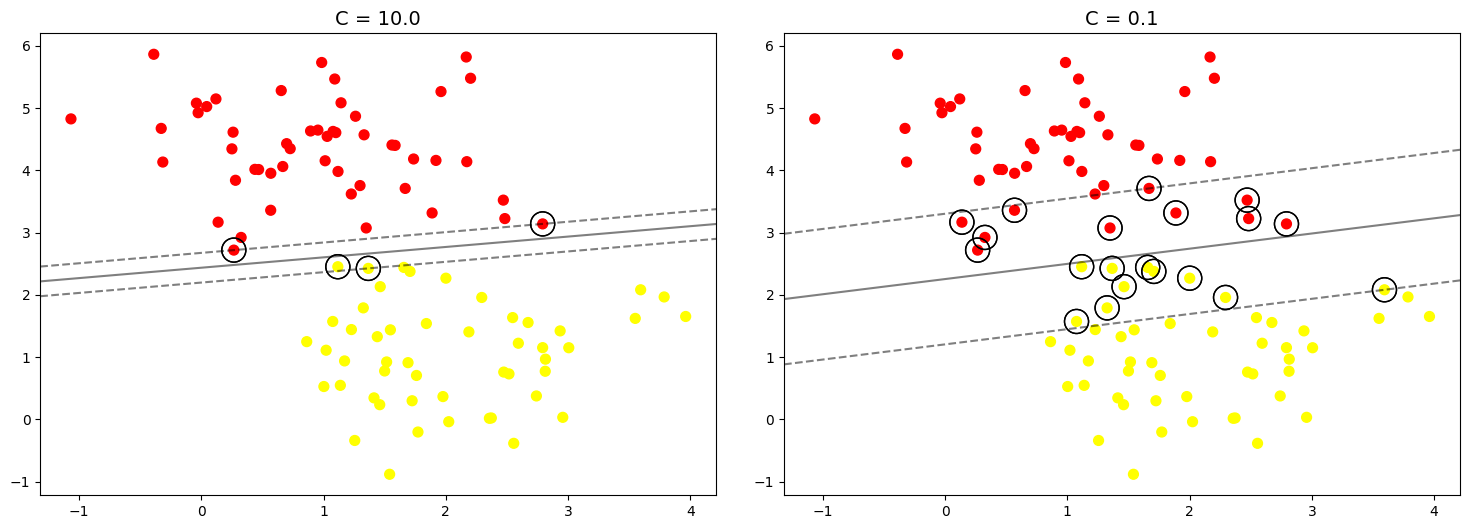

In [18]:
# Langkah 3 - Analisis Dampak Tuning (Parameter C)
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none', edgecolors='k')
    axi.set_title('C = {0:.1f}'.format(C), size=14)

>Praktikum 4

In [20]:
# Langkah 0 - Unduh Dataset
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


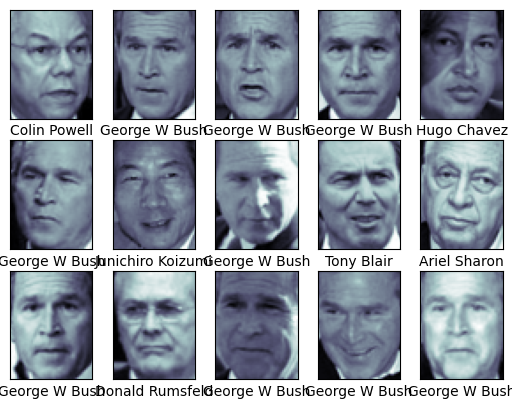

In [21]:
# Langkah 1 - Inspeksi Citra Wajah
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])

In [22]:
# Langkah 2 - Pra Pengolahan Data (Reduksi Dimensi dengan PCA)
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap
model = make_pipeline(pca, svc)

In [23]:
# Langkah 3 - Split Data Training dan Testing
from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

In [24]:
# Langkah 4 - Pembuatan Model + Tuning (GridSearchCV)
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

# Melakukan pencarian hyperparameter terbaik
%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

# Memprediksi dengan estimator terbaik
model = grid.best_estimator_
yfit = model.predict(Xtest)

CPU times: user 2min 6s, sys: 505 ms, total: 2min 7s
Wall time: 1min 21s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

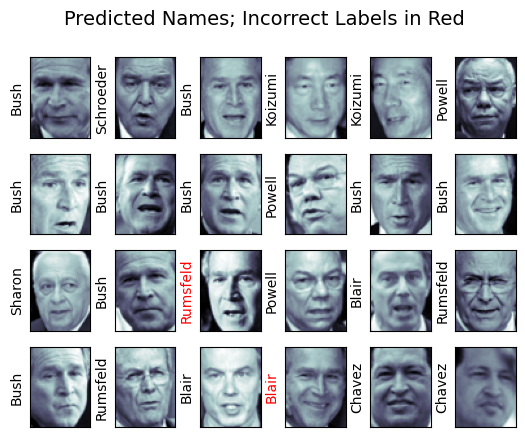

In [25]:
# Langkah 5 - Cek Hasil Prediksi Visual
fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Text(113.92222222222219, 0.5, 'predicted label')

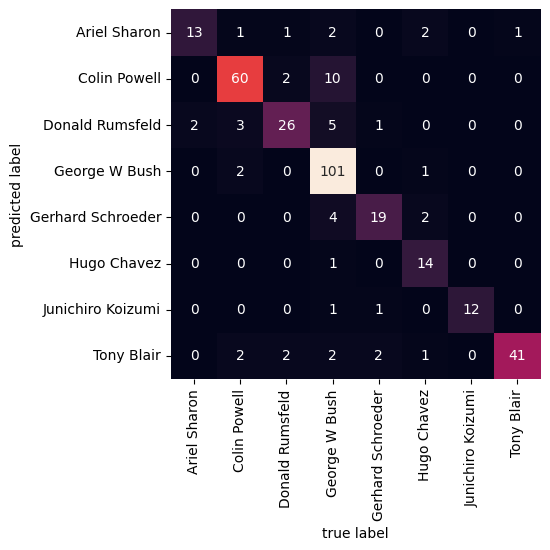

In [26]:
# Langkah 6 - Cek Performansi Model (Classification Report & Confusion Matrix)
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')

>Praktikum 5

In [29]:
# Langkah 0a - Unduh Dataset Praktikum 5 (Alternatif GitHub)
!wget -O day_night_images.zip "https://github.com/arunnthevapalan/day-night-classifier/archive/refs/heads/master.zip"
!unzip -q day_night_images.zip
!mv day-night-classifier-master/images .
!ls -la images

--2026-11-10 16:06:31--  https://github.com/arunnthevapalan/day-night-classifier/archive/refs/heads/master.zip
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://codeload.github.com/arunnthevapalan/day-night-classifier/zip/refs/heads/master [following]
--2026-11-10 16:06:31--  https://codeload.github.com/arunnthevapalan/day-night-classifier/zip/refs/heads/master
Resolving codeload.github.com (codeload.github.com)... 140.82.113.10
Connecting to codeload.github.com (codeload.github.com)|140.82.113.10|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [application/zip]
Saving to: ‘day_night_images.zip’

day_night_images.zi     [      <=>           ]  27.90M  25.6MB/s    in 1.1s    

2026-11-10 16:06:33 (25.6 MB/s) - ‘day_night_images.zip’ saved [29256847]

total 16
drwxr-xr-x 4 root root 4096 May  6  2024 .
drwxr-xr-x 1

In [30]:
# Langkah 0b - Import Library
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

# Definisikan direktori gambar training dan testing
train_dir = "images/training/"
test_dir = "images/test/"

Sampel data indeks 0: <class 'tuple'> dengan panjang tuple: 2
Pengecekan acak gambar ke-183:
Ukuran dimensi: (458, 800, 3)
Shape	: (439, 640, 3)
Label	: night


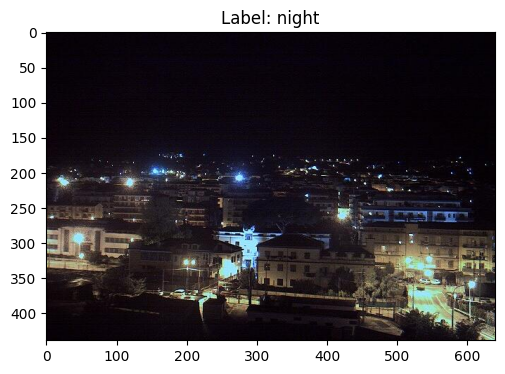

In [31]:
# Langkah 1 - Load Data dan Visualisasikan
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')
    img_list = []

    for dir in dirs:
        label = str(dir).split('/')[-1]
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)
            if img is not None:
                img_list.append((img, label))
    return img_list

# Memuat data training
train_img = load_dataset(train_dir)

# Mengecek salah satu data pada list
print("Sampel data indeks 0:", type(train_img[0]), "dengan panjang tuple:", len(train_img[0]))

# Cek ukuran gambar secara acak
pick_random = np.random.randint(0, len(train_img))
print(f'Pengecekan acak gambar ke-{pick_random}:')
print("Ukuran dimensi:", train_img[pick_random][0].shape)

# Fungsi bantu untuk visualisasi
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))
    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    plt.imshow(img)
    plt.title(f'Label: {label}')
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

# Jalankan visualisasi acak
plt.figure(figsize=(6, 4))
random_img_viz(train_img)

Gambar Terstandarisasi 108:
Ukuran dimensi (height, width, channels): (600, 1100, 3)
Shape	: (600, 1100, 3)
Label	: 0 (night)


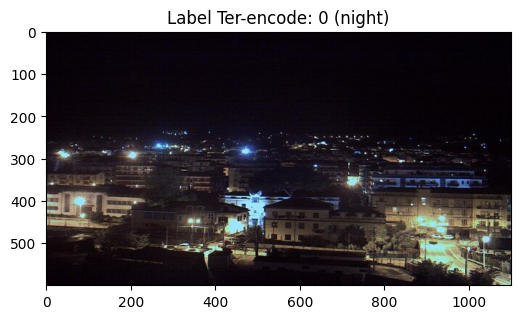

In [35]:
# Langkah 3 - Pra Pengolahan Data
def standarized_input(image):
    # Standarisasi ukuran ke width: 1100, height: 600
    std_img = cv2.resize(image, (1100, 600))
    return std_img

def label_encoder(label):
    # Encode label: day -> 1, selain itu (night) -> 0
    return 1 if label == 'day' else 0

def preprocess(img_list):
    std_img_list = []
    for item in img_list:
        image = item[0]
        label = item[1]

        std_img = standarized_input(image)
        img_label = label_encoder(label)
        std_img_list.append((std_img, img_label))
    return std_img_list

# Eksekusi preprocessing pada data training
train_std_img_list = preprocess(train_img)

# Cek kembali ukuran gambar acak hasil preprocessing
pick_random = np.random.randint(0, len(train_std_img_list))
print(f'Gambar Terstandarisasi {pick_random}:')
print("Ukuran dimensi (height, width, channels):", train_std_img_list[pick_random][0].shape)

# Fungsi visualisasi gambar terstandarisasi
def random_img_viz_std(img_list):
    rand_num = np.random.randint(0, len(img_list))
    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night'

    plt.imshow(img)
    plt.title(f'Label Ter-encode: {label} ({label_str})')
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label} ({label_str})')

# Jalankan visualisasi hasil preprocessing
plt.figure(figsize=(6, 4))
random_img_viz_std(train_std_img_list)

Gambar Latih ke-102
Rata-rata Kecerahan: 130.8899


Text(0.5, 1.0, 'Kecerahan: 130.89')

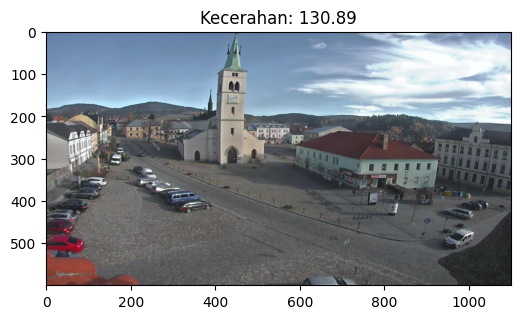

In [36]:
# Langkah 4 - Ekstraksi Fitur (Average Brightness HSV)
def avg_brightness(image):
    # Mengubah ruang warna RGB ke HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    # Mengambil channel V (Value/Kecerahan) untuk rata-rata
    sum_brightness = np.sum(img_hsv[:, :, 2])
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area
    return avg

# Uji ekstraksi fitur secara acak pada data terstandarisasi
rand_img = np.random.randint(0, len(train_std_img_list))
feature_img = train_std_img_list[rand_img][0]
avg_img = avg_brightness(feature_img)

print(f'Gambar Latih ke-{rand_img}')
print(f'Rata-rata Kecerahan: {avg_img:.4f}')
plt.figure(figsize=(6, 4))
plt.imshow(feature_img)
plt.title(f'Kecerahan: {avg_img:.2f}')

Gambar ke-154
Label Aktual: 0
Label Prediksi: 0


Text(0.5, 1.0, 'Aktual: 0 | Prediksi: 0')

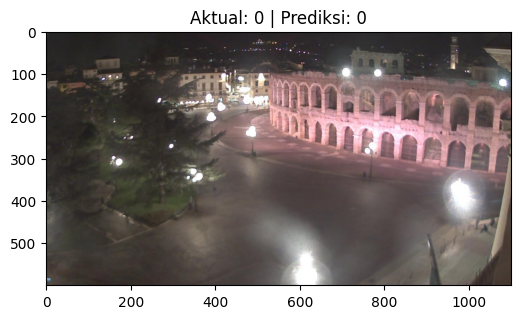

In [37]:
# Langkah 5 - Klasifikasi dengan Metode Threshold
def predict_label(img, threshold):
    avg = avg_brightness(img)
    # Jika di atas threshold, prediksi 1 (siang), sebaliknya 0 (malam)
    return 1 if avg > threshold else 0

# Uji coba prediksi secara acak pada data training
rand_img = np.random.randint(0, len(train_std_img_list))
pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

print(f'Gambar ke-{rand_img}')
print(f'Label Aktual: {train_std_img_list[rand_img][1]}')
print(f'Label Prediksi: {pred}')
plt.figure(figsize=(6, 4))
plt.imshow(train_std_img_list[rand_img][0])
plt.title(f'Aktual: {train_std_img_list[rand_img][1]} | Prediksi: {pred}')

In [38]:
# Langkah 6 - Evaluasi Manual
def evaluate(img_list, threshold):
    miss_labels = []
    for file in img_list:
        img = file[0]
        label = file[1]
        pred_label = predict_label(img, threshold)
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img
    print(f'Akurasi Evaluasi: {accuracy:.4f}')

# Evaluasi performa pada data training
print("Evaluasi Data Training (Threshold = 120):")
evaluate(train_std_img_list, threshold=120)

# Memuat, memproses, dan mengevaluasi pada data testing
test_img = load_dataset(test_dir)
test_std_img_list = preprocess(test_img)

print("\nEvaluasi Data Testing (Threshold = 120):")
evaluate(test_std_img_list, threshold=120)

Evaluasi Data Training (Threshold = 120):
Akurasi Evaluasi: 0.8417

Evaluasi Data Testing (Threshold = 120):
Akurasi Evaluasi: 0.8688


In [39]:
# Langkah 4 Alternatif - Membuat Feature Vectors
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0]) # Dapatkan rata-rata kecerahan
        img_label = img[1]             # Dapatkan label citra

        avg_list.append(img_avg)
        labels.append(img_label)

    # Susun data dalam bentuk baris dan kolom
    data = np.column_stack((avg_list, labels))
    # Buat Pandas DataFrame
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])
    return df

# Ekstraksi fitur kecerahan pada data training dan testing
train_avg_img = extract_avg_bright_feature(train_std_img_list)
test_avg_img = extract_avg_bright_feature(test_std_img_list)

# Menampilkan sampel struktur data training
print(f'Ukuran Dimensi Data Training: {train_avg_img.shape}')
print(train_avg_img.head())

Ukuran Dimensi Data Training: (240, 2)
   AVG_BRIGHT  LABELS
0  127.998211     1.0
1  105.600792     1.0
2  128.610358     1.0
3   97.989742     1.0
4  132.133823     1.0


In [40]:
# Langkah 5 - Buat Model SVM
from sklearn.svm import SVC

# Pemisahan fitur (X) dan target (y)
X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1]
X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1]

# Inisialisasi dan training model SVM (Kernel RBF default)
model = SVC()
model.fit(X_train, y_train)

SVC()

In [41]:
# Langkah 6 - Evaluasi Model SVM
from sklearn.metrics import accuracy_score

# Prediksi label pada data training
y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi label pada data testing
y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

# Menampilkan hasil evaluasi model
print(f'Akurasi Model SVM pada Data Training: {acc_train:.4f}')
print(f'Akurasi Model SVM pada Data Testing : {acc_test:.4f}')

Akurasi Model SVM pada Data Training: 0.8583
Akurasi Model SVM pada Data Testing : 0.9000


# Tugas Praktikum

### **TUGAS 1: Klasifikasi Deteksi Gender Berdasarkan Suara (voice.csv)**

**Langkah-langkah:**
1. Memuat dataset `voice.csv` menggunakan pandas.
2. Melakukan encoding label target (`label` -> 1 untuk male, 0 untuk female).
3. Memisahkan fitur ($X$) dan label ($y$).
4. Melakukan standarisasi fitur menggunakan `StandardScaler` karena SVM sangat sensitif terhadap skala data.
5. Melakukan train-test split dengan dua rasio:
   - Rasio 70:30 (`test_size = 0.3`)
   - Rasio 80:20 (`test_size = 0.2`)
6. Membangun dan melatih model SVM dengan tiga jenis kernel:
   - Linear
   - Polynomial (degree = 3)
   - RBF
7. Menghitung akurasi untuk setiap kombinasi dan menampilkan hasilnya dalam bentuk tabel DataFrame.

In [45]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1. Memuat dataset
df_voice = pd.read_csv('voice.csv')

# 2. Encoding label target
le = LabelEncoder()
df_voice['label'] = le.fit_transform(df_voice['label'])

# 3. Memisahkan fitur dan label
X_voice = df_voice.iloc[:, :-1].values
y_voice = df_voice.iloc[:, -1].values

# 4. Standarisasi fitur
scaler = StandardScaler()
X_voice_scaled = scaler.fit_transform(X_voice)

# Inisialisasi list untuk menyimpan hasil tabulasi
results = []

# Definisikan rasio split dan kernel yang digunakan
ratios = [0.3, 0.2]  # Test size untuk representasi 70:30 dan 80:20
kernels = ['linear', 'poly', 'rbf']

# 5. Iterasi untuk setiap rasio split dan kernel
for test_size in ratios:
    split_label = f"{(1-test_size)*100:.0f}:{(test_size)*100:.0f}"
    X_train, X_test, y_train, y_test = train_test_split(
        X_voice_scaled, y_voice, test_size=test_size, random_state=42, stratify=y_voice
    )

    for kernel in kernels:
        # Definisikan model SVM sesuai dengan jenis kernel
        if kernel == 'poly':
            model = SVC(kernel=kernel, degree=3, random_state=42)
        else:
            model = SVC(kernel=kernel, random_state=42)

        # Latih model
        model.fit(X_train, y_train)

        # Prediksi dan evaluasi akurasi
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)

        # Simpan performansi
        results.append({
            'Rasio Split': split_label,
            'Kernel SVM': kernel.capitalize(),
            'Akurasi Pengujian': f"{acc * 100:.2f}%"
        })

# 7. Menampilkan hasil tabulasi performansi
df_performance = pd.DataFrame(results)
print("=========================================================")
print("TABEL PERFORMANSI EVALUASI SVM PADA DATASET VOICE.CSV")
print("=========================================================")
display(df_performance)

TABEL PERFORMANSI EVALUASI SVM PADA DATASET VOICE.CSV


,Rasio Split,Kernel SVM,Akurasi Pengujian
0,70:30,Linear,97.90%
1,70:30,Poly,95.90%
2,70:30,Rbf,98.32%
3,80:20,Linear,97.48%
4,80:20,Poly,95.74%
5,80:20,Rbf,98.26%


In [47]:
# =====================================================================
# TUGAS 2: Klasifikasi Citra Siang dan Malam (SVM RBF + Fitur Histogram)
# =====================================================================
# Langkah-langkah:
# 1. Menggunakan data citra terstandarisasi dari Praktikum 5.
# 2. Ekstraksi Fitur Histogram Warna 3 Dimensi (HSV Histogram).
# 3. Pembagian data latih dan uji menggunakan rasio 80:20.
# 4. Hyperparameter Tuning menggunakan GridSearchCV.
# 5. Evaluasi performansi model terbaik pada data uji.
print("Pra-pemrosesan Tugas 2 siap dijalankan.")

Pra-pemrosesan Tugas 2 siap dijalankan.


### **TUGAS 2: Klasifikasi Citra Siang dan Malam (SVM RBF + Fitur Histogram)**

**Langkah-langkah:**
1. Menggunakan data citra terstandarisasi dari Praktikum 5.
2. Ekstraksi Fitur Histogram Warna 3 Dimensi (HSV Histogram).
3. Pembagian data latih dan uji menggunakan rasio 80:20.
4. Hyperparameter Tuning menggunakan GridSearchCV untuk mencari kombinasi parameter terbaik.
5. Evaluasi performansi model terbaik pada data uji.

In [44]:
import cv2
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Fungsi ekstraksi fitur Histogram Warna 3D (HSV)
def extract_hsv_hist_feature(image, bins=(8, 8, 8)):
    # Konversi citra dari RGB ke ruang warna HSV
    hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    # Hitung histogram 3 dimensi untuk seluruh channel
    hist = cv2.calcHist([hsv_image], [0, 1, 2], None, bins, [0, 180, 0, 256, 0, 256])
    # Normalisasi histogram
    cv2.normalize(hist, hist)
    # Meratakan matriks histogram menjadi vektor fitur 1 dimensi
    return hist.flatten()

# 2. Mempersiapkan seluruh dataset gabungan
# Ambil data terstandarisasi dari Praktikum 5 (yang sudah disalin dan di-resize)
all_images_and_labels = train_std_img_list + test_std_img_list

X_hist = []
y_labels = []

for img, label in all_images_and_labels:
    features = extract_hsv_hist_feature(img)
    X_hist.append(features)
    y_labels.append(label)

X_hist = np.array(X_hist)
y_labels = np.array(y_labels)

# 3. Split dataset dengan rasio 80:20
X_train_img, X_test_img, y_train_img, y_test_img = train_test_split(
    X_hist, y_labels, test_size=0.20, random_state=42, stratify=y_labels
)

print(f"Jumlah data latih (80%): {X_train_img.shape[0]} sampel")
print(f"Jumlah data uji (20%): {X_test_img.shape[0]} sampel")

# 4. Hyperparameter Tuning untuk SVM dengan kernel RBF
# Menentukan ruang pencarian hyperparameter C dan gamma
param_grid_rbf = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1.0]
}

# Inisialisasi model SVM dengan kernel RBF
svm_rbf = SVC(kernel='rbf', random_state=42)

# Gunakan GridSearchCV untuk mencari kombinasi parameter terbaik
grid_search = GridSearchCV(svm_rbf, param_grid_rbf, cv=5, scoring='accuracy')
grid_search.fit(X_train_img, y_train_img)

# Mendapatkan parameter terbaik hasil pencarian
best_svm_model = grid_search.best_estimator_

# 5. Evaluasi Performansi Akhir
y_train_pred_img = best_svm_model.predict(X_train_img)
y_test_pred_img = best_svm_model.predict(X_test_img)

acc_train_img = accuracy_score(y_train_img, y_train_pred_img)
acc_test_img = accuracy_score(y_test_img, y_test_pred_img)

print("\n=========================================================")
print("HASIL TUNING HYPERPARAMETER DAN EVALUASI SVM KERNEL RBF")
print("=========================================================")
print(f"Parameter Terbaik  : {grid_search.best_params_}")
print(f"Akurasi Data Latih : {acc_train_img * 100:.2f}%")
print(f"Akurasi Data Uji   : {acc_test_img * 100:.2f}%")
print("\nClassification Report Data Uji:")
print(classification_report(y_test_img, y_test_pred_img, target_names=['Night', 'Day']))

Jumlah data latih (80%): 320 sampel
Jumlah data uji (20%): 80 sampel

HASIL TUNING HYPERPARAMETER DAN EVALUASI SVM KERNEL RBF
Parameter Terbaik  : {'C': 1, 'gamma': 'scale'}
Akurasi Data Latih : 100.00%
Akurasi Data Uji   : 100.00%

Classification Report Data Uji:
              precision    recall  f1-score   support

       Night       1.00      1.00      1.00        40
         Day       1.00      1.00      1.00        40

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80

